In [ ]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU")

from google.colab import drive
drive.mount('/content/drive')

True
Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
!python -u paper1.py validate

inception: 1649402 params (expected 1649402)
alexnet: 1387786 params (expected 1387786)
mlp1x512: 1209866 params (expected 1209866)
100% 170M/170M [21:45<00:00, 131kB/s]
standardization: mean|max|=1.21e-06, std range=[1.0000,1.0000], floor hits train=0 test=0
p=0.0: mask frac 0.0000, realized changed 0.0000 (expect ~0.000)
p=0.2: mask frac 0.2006, realized changed 0.1803 (expect ~0.180)
p=0.5: mask frac 0.5026, realized changed 0.4518 (expect ~0.450)
p=1.0: mask frac 1.0000, realized changed 0.8986 (expect ~0.900)
shuffled_pixels (50000, 3, 28, 28) test: (10000, 3, 28, 28)
random_pixels (50000, 3, 28, 28) test: None
gaussian (50000, 3, 28, 28) test: None
ALL VALIDATION CHECKS PASSED


In [ ]:
!python -u paper1.py sweep --tier full \
  --out "/content/drive/MyDrive/paper1_results"

100% 170M/170M [09:36<00:00, 295kB/s]
99 runs
skip (exists): /content/drive/MyDrive/paper1_results/runs/inception_label_corruption_p0.00_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/inception_label_corruption_p0.10_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/inception_label_corruption_p0.20_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/inception_label_corruption_p0.30_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/inception_label_corruption_p0.40_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/inception_label_corruption_p0.50_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/inception_label_corruption_p0.60_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/inception_label_corruption_p0.70_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/inception_label_corruption_p0.80_s0.json
  [inception label_corruption p=0.9 s=0] step 0 loss 2.3027 acc

In [ ]:
results_dir = "/content/drive/MyDrive/paper1_results/runs"

!python -u paper1.py aggregate \
    --out "/content/drive/MyDrive/paper1_results"

wrote /content/drive/MyDrive/paper1_results/fig1a.csv (121 rows)
wrote /content/drive/MyDrive/paper1_results/fig1b.csv (33 rows)
wrote /content/drive/MyDrive/paper1_results/fig1c.csv (11 rows)

Anchor check (mean final test error; Table 1-implied p=0 reference):
  inception p=0.0: ours 0.1436 vs reference ~0.1425
  inception p=1.0: ours 0.9007 vs reference ~0.9000
censored runs under primary criterion: 0


In [ ]:
path = "/content/drive/MyDrive/paper1_results/fig1b.csv"
df = pd.read_csv(path)
display(df)

,criterion,arch,p,seed,conv_step,censored,T0_mean,t_rel,t_rel_is_lower_bound
0,train_acc_0.99_k2,inception,0.0,0,5200.0,0,5200.0,1.000000,0
1,train_acc_0.99_k2,inception,0.1,0,7200.0,0,5200.0,1.384615,0
2,train_acc_0.99_k2,inception,0.2,0,8800.0,0,5200.0,1.692308,0
3,train_acc_0.99_k2,inception,0.3,0,10000.0,0,5200.0,1.923077,0
4,train_acc_0.99_k2,inception,0.4,0,10400.0,0,5200.0,2.000000,0
5,train_acc_0.99_k2,inception,0.5,0,11600.0,0,5200.0,2.230769,0
6,train_acc_0.99_k2,inception,0.6,0,12400.0,0,5200.0,2.384615,0
7,train_acc_0.99_k2,inception,0.7,0,13000.0,0,5200.0,2.500000,0
8,train_acc_0.99_k2,inception,0.8,0,14000.0,0,5200.0,2.692308,0
9,train_acc_0.99_k2,inception,0.9,0,15800.0,0,5200.0,3.038462,0


In [ ]:
plot_df = df[(df["criterion"] == "train_acc_0.99_k2") & (df["arch"] == "inception") & (df["seed"] == 0)]

display(plot_df)

,criterion,arch,p,seed,conv_step,censored,T0_mean,t_rel,t_rel_is_lower_bound
0,train_acc_0.99_k2,inception,0.0,0,5200.0,0,5200.0,1.000000,0
1,train_acc_0.99_k2,inception,0.1,0,7200.0,0,5200.0,1.384615,0
2,train_acc_0.99_k2,inception,0.2,0,8800.0,0,5200.0,1.692308,0
3,train_acc_0.99_k2,inception,0.3,0,10000.0,0,5200.0,1.923077,0
4,train_acc_0.99_k2,inception,0.4,0,10400.0,0,5200.0,2.000000,0
5,train_acc_0.99_k2,inception,0.5,0,11600.0,0,5200.0,2.230769,0
6,train_acc_0.99_k2,inception,0.6,0,12400.0,0,5200.0,2.384615,0
7,train_acc_0.99_k2,inception,0.7,0,13000.0,0,5200.0,2.500000,0
8,train_acc_0.99_k2,inception,0.8,0,14000.0,0,5200.0,2.692308,0
9,train_acc_0.99_k2,inception,0.9,0,15800.0,0,5200.0,3.038462,0


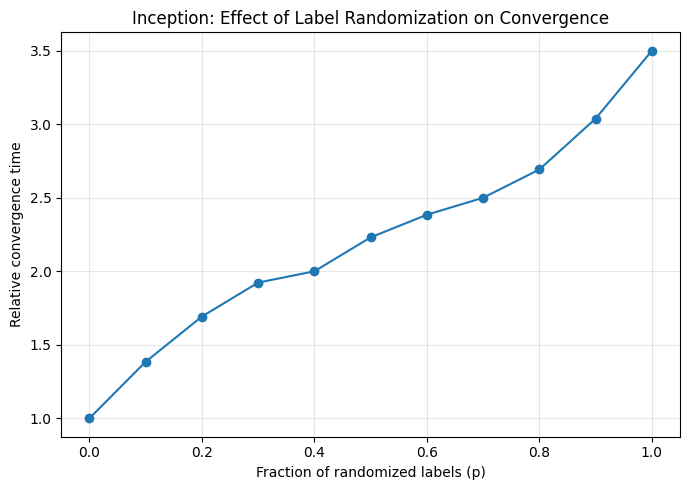

In [ ]:
plt.figure(figsize=(7, 5))

plt.plot(plot_df["p"], plot_df["t_rel"], marker="o")

plt.xlabel("Fraction of randomized labels (p)")
plt.ylabel("Relative convergence time")
plt.title("Inception: Effect of Label Randomization on Convergence")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
!python -u paper1.py sweep --tier full --archs alexnet --seeds 1 --out "/content/drive/MyDrive/paper1_results"

100% 170M/170M [22:27<00:00, 127kB/s]
11 runs
skip (exists): /content/drive/MyDrive/paper1_results/runs/alexnet_label_corruption_p0.00_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/alexnet_label_corruption_p0.10_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/alexnet_label_corruption_p0.20_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/alexnet_label_corruption_p0.30_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/alexnet_label_corruption_p0.40_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/alexnet_label_corruption_p0.50_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/alexnet_label_corruption_p0.60_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/alexnet_label_corruption_p0.70_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/alexnet_label_corruption_p0.80_s0.json
skip (exists): /content/drive/MyDrive/paper1_results/runs/alexnet_label_corruptio

In [ ]:
!python -u paper1.py sweep --tier full --archs mlp1x512 --seeds 1 --out "/content/drive/MyDrive/paper1_results"

11 runs
  [mlp1x512 label_corruption p=0.0 s=0] step 0 loss 2.3259 acc 0.0995 test_err 0.8999
  [mlp1x512 label_corruption p=0.0 s=0] step 1000 loss 1.2170 acc 0.5748 test_err 0.5085
  [mlp1x512 label_corruption p=0.0 s=0] step 2000 loss 0.9776 acc 0.6605 test_err 0.49060000000000004
  [mlp1x512 label_corruption p=0.0 s=0] step 3000 loss 0.7660 acc 0.7448 test_err 0.48319999999999996
  [mlp1x512 label_corruption p=0.0 s=0] step 4000 loss 0.6011 acc 0.8014 test_err 0.48160000000000003
  [mlp1x512 label_corruption p=0.0 s=0] step 5000 loss 0.4832 acc 0.8452 test_err 0.48160000000000003
  [mlp1x512 label_corruption p=0.0 s=0] step 6000 loss 0.3497 acc 0.8990 test_err 0.488
  [mlp1x512 label_corruption p=0.0 s=0] step 7000 loss 0.2598 acc 0.9323 test_err 0.48260000000000003
  [mlp1x512 label_corruption p=0.0 s=0] step 8000 loss 0.1903 acc 0.9580 test_err 0.487
  [mlp1x512 label_corruption p=0.0 s=0] step 9000 loss 0.1382 acc 0.9772 test_err 0.48129999999999995
  [mlp1x512 label_corruption 

In [ ]:
!python -u paper1.py aggregate \
    --out "/content/drive/MyDrive/paper1_results"

wrote /content/drive/MyDrive/paper1_results/fig1a.csv (121 rows)
wrote /content/drive/MyDrive/paper1_results/fig1b.csv (99 rows)
wrote /content/drive/MyDrive/paper1_results/fig1c.csv (33 rows)

Anchor check (mean final test error; Table 1-implied p=0 reference):
  inception p=0.0: ours 0.1436 vs reference ~0.1425
  inception p=1.0: ours 0.9007 vs reference ~0.9000
  alexnet p=0.0: ours 0.2293 vs reference ~0.2393
  alexnet p=1.0: ours 0.8991 vs reference ~0.9000
  mlp1x512 p=0.0: ours 0.4787 vs reference ~0.4949
  mlp1x512 p=1.0: ours 0.8999 vs reference ~0.9000
censored runs under primary criterion: 0


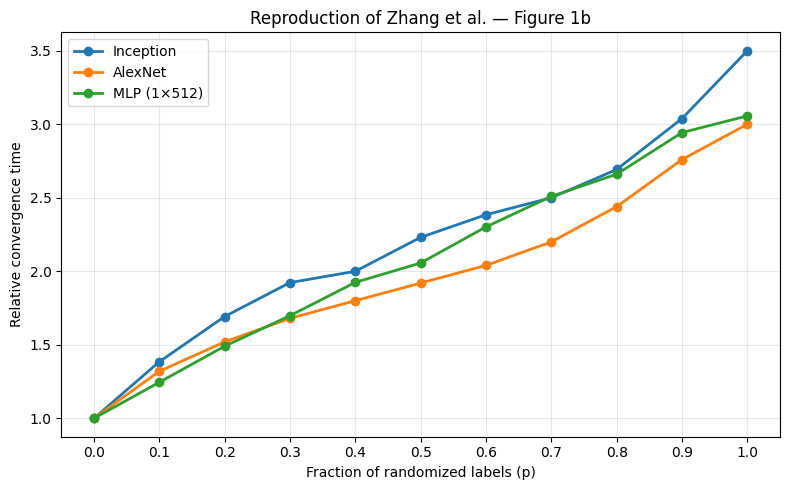

In [ ]:
path = "/content/drive/MyDrive/paper1_results/fig1b.csv"
df = pd.read_csv(path)

# Use the primary convergence criterion
plot_df = df[(df["criterion"] == "train_acc_0.99_k2") & (df["censored"] == 0)].copy()

plt.figure(figsize=(8, 5))

for arch, label in [("inception", "Inception"), ("alexnet", "AlexNet"), ("mlp1x512", "MLP (1×512)")]:
    subset = plot_df[plot_df["arch"] == arch]

    # Average across seeds, if multiple seeds exist
    curve = (subset.groupby("p", as_index=False)["t_rel"].mean().sort_values("p"))

    plt.plot(curve["p"],
        curve["t_rel"],
        marker="o",
        linewidth=2,
        label=label)

plt.xlabel("Fraction of randomized labels (p)")
plt.ylabel("Relative convergence time")
plt.title("Reproduction of Zhang et al. — Figure 1b")

plt.xticks([i / 10 for i in range(11)])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/paper1_results/fig1b_reproduced.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

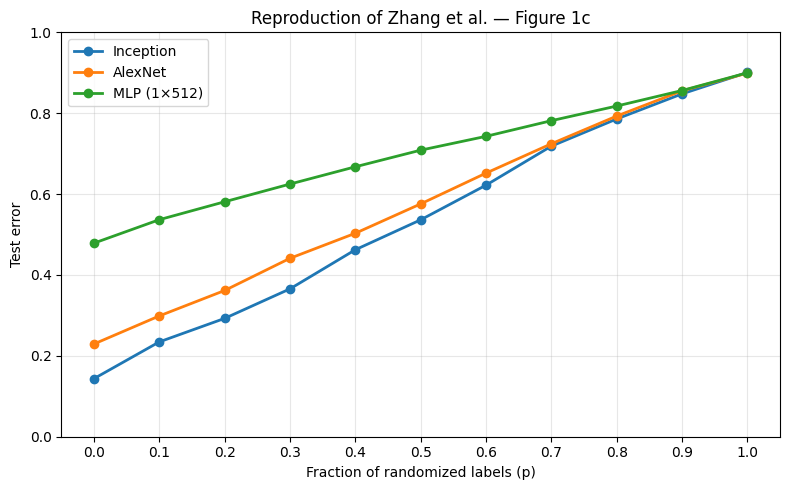

In [ ]:
root = "/content/drive/MyDrive/paper1_results"
df = pd.read_csv(f"{root}/fig1c.csv")

# Use seed 0 consistently across all architectures
df = df[df["seed"] == 0]

plt.figure(figsize=(8, 5))

for arch, label in [("inception", "Inception"), ("alexnet", "AlexNet"), ("mlp1x512", "MLP (1×512)")]:
    subset = df[df["arch"] == arch].sort_values("p")

    plt.plot(subset["p"],
        subset["final_test_err"],
        marker="o",
        linewidth=2,
        label=label)

plt.xlabel("Fraction of randomized labels (p)")
plt.ylabel("Test error")
plt.title("Reproduction of Zhang et al. — Figure 1c")

plt.xticks([i / 10 for i in range(11)])
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{root}/fig1c_reproduced.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
!python -u paper1.py fig1a --tier minimal --seeds 1 --out "/content/drive/MyDrive/paper1_results"

  [inception shuffled_pixels p=0.0 s=0] step 0 loss 2.3028 acc 0.1000 test_err 0.9
  [inception shuffled_pixels p=0.0 s=0] step 1000 loss 1.7645 acc 0.4088 test_err 0.6172
  [inception shuffled_pixels p=0.0 s=0] step 2000 loss 1.0446 acc 0.6224 test_err 0.49039999999999995
  [inception shuffled_pixels p=0.0 s=0] step 3000 loss 0.8343 acc 0.6925 test_err 0.48129999999999995
  [inception shuffled_pixels p=0.0 s=0] step 4000 loss 0.5975 acc 0.7874 test_err 0.49319999999999997
  [inception shuffled_pixels p=0.0 s=0] step 5000 loss 0.3764 acc 0.8633 test_err 0.49350000000000005
  [inception shuffled_pixels p=0.0 s=0] step 6000 loss 0.1882 acc 0.9319 test_err 0.48729999999999996
  [inception shuffled_pixels p=0.0 s=0] step 7000 loss 0.0796 acc 0.9730 test_err 0.47729999999999995
Converged at step 7400; stopping early.
DONE /content/drive/MyDrive/paper1_results/runs/inception_shuffled_pixels_p0.00_s0.json: conv_step=7400 final_test_err=0.46499999999999997
  [inception random_pixels p=0.0 s=0]

In [ ]:
!python -u paper1.py aggregate --out "/content/drive/MyDrive/paper1_results"

wrote /content/drive/MyDrive/paper1_results/fig1a.csv (286 rows)
wrote /content/drive/MyDrive/paper1_results/fig1b.csv (99 rows)
wrote /content/drive/MyDrive/paper1_results/fig1c.csv (33 rows)

Anchor check (mean final test error; Table 1-implied p=0 reference):
  inception p=0.0: ours 0.1436 vs reference ~0.1425
  inception p=1.0: ours 0.9007 vs reference ~0.9000
  alexnet p=0.0: ours 0.2293 vs reference ~0.2393
  alexnet p=1.0: ours 0.8991 vs reference ~0.9000
  mlp1x512 p=0.0: ours 0.4787 vs reference ~0.4949
  mlp1x512 p=1.0: ours 0.8999 vs reference ~0.9000
censored runs under primary criterion: 0


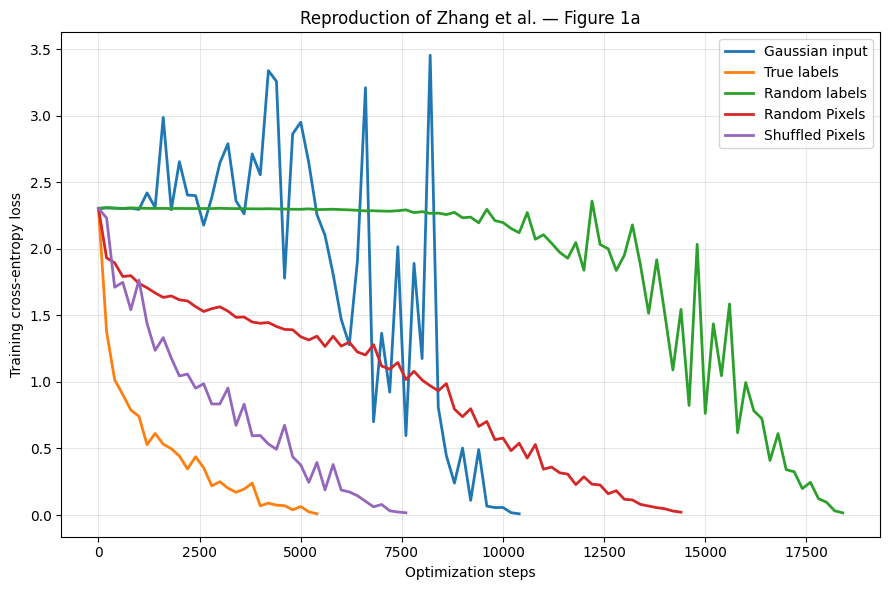

In [ ]:

df_1a = pd.read_csv(f"{root}/fig1a.csv")
plot_df = df_1a[df_1a["seed"] == 0].copy()

plt.figure(figsize=(9, 6))

labels = {"true_labels": "True labels",
    "random_labels": "Random labels",
    "fixed_permutation": "Fixed pixel permutation",
    "random_permutation": "Random pixel permutation",
    "gaussian": "Gaussian input"}

for setting in plot_df["setting"].unique():
    subset = (plot_df[plot_df["setting"] == setting]
        .sort_values("step"))

    plt.plot(subset["step"],
        subset["train_loss_eval"],
        linewidth=2,
        label=labels.get(setting, setting.replace("_", " ").title()))

plt.xlabel("Optimization steps")
plt.ylabel("Training cross-entropy loss")
plt.title("Reproduction of Zhang et al. — Figure 1a")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{root}/fig1a_reproduced.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()